# P09: accuracy and cost, side by side

The director asks whether a neural network is worth it on kiosks with modest CPUs and a small budget. We now have, for every model,
its accuracy. This notebook adds what it **costs to run**: the time to process one image on a CPU, and the size of the network.
It trains nothing and scores nothing on the test set (ADR 0003): it only measures speed and reads the results already saved.

What exactly is measured:

- **The whole network that would run on the kiosk**, from the image to the 5 genre scores. For the ResNets this is the entire
  pretrained network (about 11 million weights for ResNet-18), not only the 2,565 weights we trained: the frozen part has to run too.
- **One image at a time** (batch of 1), as a visitor pointing a camera would. All the models are timed in **9 rounds, in a different
  random order each round**, so that a slow drift of the computer (it heats up, another program runs) hits every model alike. The
  table gives the median over the rounds, and the smallest and largest round.
- **A built-in control:** the two ResNet-18 rows at 224 px are the same network (training the last block changes the weights, not
  the shape). Their difference shows the noise of the measurement.
- **1 CPU thread** (a pessimistic stand-in for a modest kiosk) and **all the threads** of this computer.
- **Not included:** reading and resizing the photo (the same for every model, a few milliseconds), and the camera itself.
- The numbers belong to **this computer**. A kiosk will be slower or faster, but the *ratios* between models should hold.

For a reliable timing, close other heavy programs (and other notebooks) while this runs.

In [1]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

from deep_learning_project_waerniers_lamy.vision.utils import (
    build_cnn, build_dense, build_resnet_head, load_result, pretrained_resnet, summary)

# For each model: the run whose architecture we time, the run that gives its validation score, the run that gives its test score.
MODELS = {
    "dense baseline, 32 px": ("dense_baseline", "dense_baseline", "dense_baseline"),
    "CNN 3 blocks, 64 px": ("cnn_longer", "cnn_longer", "cnn_longer"),
    "CNN 4 blocks, 64 px": ("cnn_deeper", "cnn_deeper_5seeds", "cnn_deeper"),
    "ResNet-18 frozen, 64 px": ("resnet18_head_64px", "resnet18_head_64px", None),
    "ResNet-18 frozen, 112 px": ("resnet18_head_112px", "resnet18_head_112px", None),
    "ResNet-18 frozen, 224 px": ("resnet18_head", "resnet18_head", "resnet18_head"),
    "ResNet-18 + layer4, 224 px": ("resnet18_layer4", "resnet18_layer4", "resnet18_layer4"),
    "ResNet-50 frozen, 224 px": ("resnet50_head", "resnet50_head", None),
}

table = summary()


def saved_run(name):
    """The earliest saved run with this name."""
    rows = table[table["name"] == name].sort_values("date")
    return load_result(rows["file"].iloc[0])


def inference_model(config):
    """The whole network that would run on the kiosk: from the image tensor to the 5 genre scores."""
    kind = config["model"]
    if kind == "dense":
        return nn.Sequential(nn.Flatten(), build_dense(config))
    if kind == "cnn":
        return build_cnn(config)
    r = pretrained_resnet(kind)  # "resnet18" or "resnet50": the frozen part, up to the average pooling
    backbone = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4, r.avgpool, nn.Flatten())
    return nn.Sequential(backbone, build_resnet_head({**config, "finetune": "head"}))  # training the last block does not change the shape


ROUNDS = 9  # every model is timed in this many rounds, in a different random order each time
REPEATS = 10  # runs per timing: the median of these is one measurement


def time_all(networks, threads):
    """Time in ms to process one image, for every network: one value per round and per model (rounds are interleaved)."""
    previous = torch.get_num_threads()
    torch.set_num_threads(threads)
    inputs = {label: torch.randn(1, 3, size, size) for label, (net, size) in networks.items()}
    measurements = {label: [] for label in networks}
    with torch.no_grad():
        for label, (net, size) in networks.items():  # warm-up, not counted
            for _ in range(3):
                net(inputs[label])
        labels = list(networks)
        for _ in range(ROUNDS):
            random.shuffle(labels)  # a different order every round: a slow drift hits all the models alike
            for label in labels:
                runs = []
                for _ in range(REPEATS):
                    start = time.perf_counter()
                    networks[label][0](inputs[label])
                    runs.append(time.perf_counter() - start)
                measurements[label].append(1000 * float(np.median(runs)))
    torch.set_num_threads(previous)
    return pd.DataFrame(measurements)  # one row per round, one column per model


ALL_THREADS = torch.get_num_threads()
print("threads available on this computer:", ALL_THREADS)

threads available on this computer: 4


## 1. What would run on the kiosk

We rebuild the whole network of each model from its saved config, and count its weights. The size on disk assumes 4 bytes per
weight. Note the ResNets: only 2,565 weights were trained for the frozen ResNet-18, but the pretrained network around it is the
real size of the model.

In [2]:
networks = {}
rows = []
for label, (cost_run, _, _) in MODELS.items():
    config = saved_run(cost_run)["config"]
    net = inference_model(config).eval()
    networks[label] = (net, config["image_size"])
    n = sum(p.numel() for p in net.parameters())
    rows.append({"model": label, "weights (millions)": n / 1e6, "size on disk (MB)": 4 * n / 1e6})
pd.DataFrame(rows).set_index("model").round(2)

,weights (millions),size on disk (MB)
model,,
"dense baseline, 32 px",0.39,1.58
"CNN 3 blocks, 64 px",0.02,0.10
"CNN 4 blocks, 64 px",0.10,0.39
"ResNet-18 frozen, 64 px",11.18,44.72
"ResNet-18 frozen, 112 px",11.18,44.72
"ResNet-18 frozen, 224 px",11.18,44.72
"ResNet-18 + layer4, 224 px",11.18,44.72
"ResNet-50 frozen, 224 px",23.52,94.07


## 2. Time to process one image

One image at a time. Timing the models one after another is unfair: the computer slowly changes (it heats up, other programs run) and
the models timed last pay for it. So we time **all the models in 9 rounds, in a different random order each round**, and keep the
median over the rounds, with the smallest and largest round as the range. About a minute.

**A control:** the two ResNet-18 rows at 224 px are the same network, so they must cost the same. Their difference shows the noise of
the measurement: differences between models smaller than that should not be read as real.

In [3]:
one_thread = time_all(networks, 1)
all_threads = time_all(networks, ALL_THREADS)

timings = pd.DataFrame({
    "1 thread (ms)": one_thread.median(),
    "1 thread, smallest round": one_thread.min(),
    "1 thread, largest round": one_thread.max(),
    f"{ALL_THREADS} threads (ms)": all_threads.median(),
    f"{ALL_THREADS} threads, smallest round": all_threads.min(),
    f"{ALL_THREADS} threads, largest round": all_threads.max(),
})
timings["images per second, 1 thread"] = 1000 / timings["1 thread (ms)"]

same_a, same_b = "ResNet-18 frozen, 224 px", "ResNet-18 + layer4, 224 px"
gap_one = abs(timings.loc[same_a, "1 thread (ms)"] - timings.loc[same_b, "1 thread (ms)"])
gap_all = abs(timings.loc[same_a, f"{ALL_THREADS} threads (ms)"] - timings.loc[same_b, f"{ALL_THREADS} threads (ms)"])
print(f"Control: {same_a} and {same_b} are the same network. They differ by {gap_one:.1f} ms with 1 thread "
      f"and {gap_all:.1f} ms with {ALL_THREADS} threads: that is the noise of the measurement.")
timings.round(1)

Control: ResNet-18 frozen, 224 px and ResNet-18 + layer4, 224 px are the same network. They differ by 0.1 ms with 1 thread and 0.5 ms with 4 threads: that is the noise of the measurement.


,1 thread (ms),"1 thread, smallest round","1 thread, largest round",4 threads (ms),"4 threads, smallest round","4 threads, largest round","images per second, 1 thread"
"dense baseline, 32 px",0.1,0.1,0.1,0.1,0.1,0.1,14184.4
"CNN 3 blocks, 64 px",1.7,1.5,2.1,1.0,0.7,1.2,589.6
"CNN 4 blocks, 64 px",2.2,1.9,3.3,1.3,0.8,1.5,464.1
"ResNet-18 frozen, 64 px",10.5,9.8,12.5,7.3,6.5,8.3,95.1
"ResNet-18 frozen, 112 px",21.6,19.3,28.1,15.1,12.3,15.6,46.3
"ResNet-18 frozen, 224 px",70.3,64.8,81.8,42.5,35.4,45.4,14.2
"ResNet-18 + layer4, 224 px",70.5,66.0,81.9,41.9,34.1,58.5,14.2
"ResNet-50 frozen, 224 px",139.1,134.9,159.4,94.2,79.1,99.2,7.2


## 3. Accuracy and cost together

Validation accuracy is the mean over 5 seeds when we ran several, otherwise the best epoch of one seed (the "basis" column).
The test score exists only for the models we scored once on museum B (ADR 0003); it is empty for the others, which is on purpose.

In [4]:
def validation_accuracy(run_name):
    """Validation accuracy in %: the mean over seeds when we ran several, else the best epoch of one seed."""
    row = table[table["name"] == run_name].sort_values("date").iloc[0]
    if row["val_acc_mean"] == row["val_acc_mean"]:  # not NaN
        return 100 * row["val_acc_mean"], "5 seeds"
    return 100 * row["best_val_acc"], "1 seed"


def test_accuracy(run_name):
    """Test accuracy in %, or NaN if this run was not scored on museum B."""
    if run_name is None:
        return np.nan
    return 100 * table[table["name"] == run_name].sort_values("date").iloc[0]["test_acc"]


summary_table = pd.DataFrame({
    label: {
        "validation (%)": validation_accuracy(val_run)[0],
        "basis": validation_accuracy(val_run)[1],
        "test (%)": test_accuracy(test_run),
        "weights (millions)": sum(p.numel() for p in networks[label][0].parameters()) / 1e6,
        "1 thread (ms)": timings.loc[label, "1 thread (ms)"],
        f"{ALL_THREADS} threads (ms)": timings.loc[label, f"{ALL_THREADS} threads (ms)"],
    }
    for label, (_, val_run, test_run) in MODELS.items()
}).T
numbers = [c for c in summary_table.columns if c != "basis"]
summary_table[numbers] = summary_table[numbers].astype(float)  # the "basis" text made every column text
summary_table.round({"validation (%)": 1, "test (%)": 1, "weights (millions)": 2, "1 thread (ms)": 1, f"{ALL_THREADS} threads (ms)": 1})

,validation (%),basis,test (%),weights (millions),1 thread (ms),4 threads (ms)
"dense baseline, 32 px",39.0,5 seeds,41.8,0.39,0.1,0.1
"CNN 3 blocks, 64 px",60.8,1 seed,63.7,0.02,1.7,1.0
"CNN 4 blocks, 64 px",58.4,5 seeds,60.5,0.10,2.2,1.3
"ResNet-18 frozen, 64 px",70.2,5 seeds,NaN,11.18,10.5,7.3
"ResNet-18 frozen, 112 px",75.4,5 seeds,NaN,11.18,21.6,15.1
"ResNet-18 frozen, 224 px",80.3,5 seeds,84.5,11.18,70.3,42.5
"ResNet-18 + layer4, 224 px",83.3,1 seed,86.0,11.18,70.5,41.9
"ResNet-50 frozen, 224 px",81.9,5 seeds,NaN,23.52,139.1,94.2


## 4. The picture

Left: validation accuracy against the time to process one image (1 thread, logarithmic axis): the further up and to the left, the
better. Right: validation against test accuracy, for the models scored on museum B.

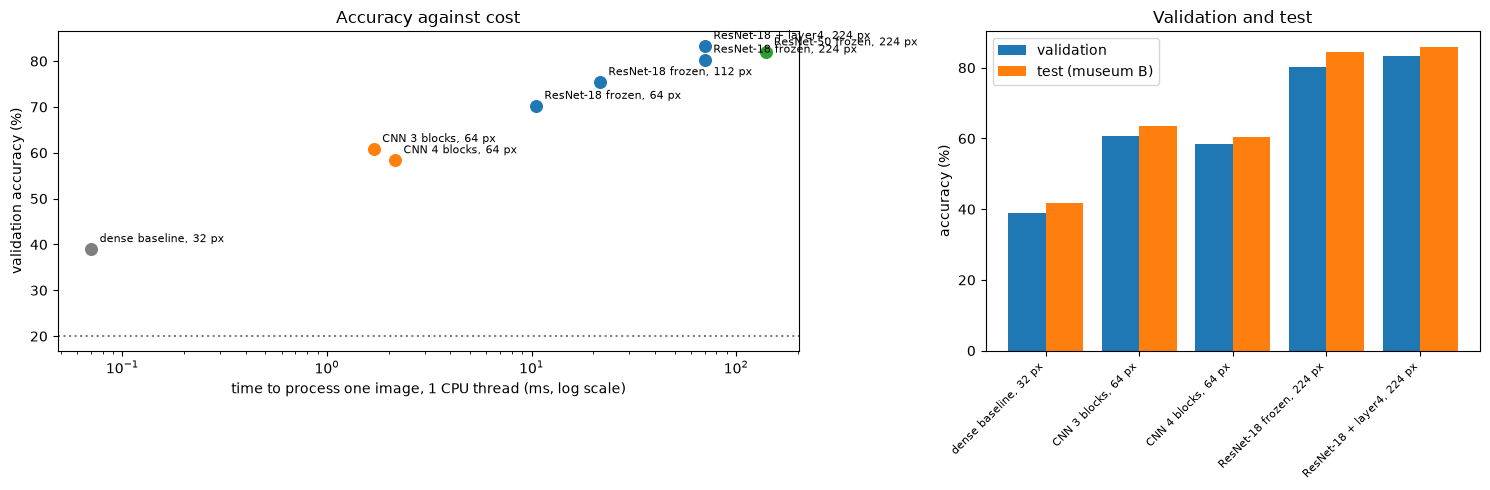

In [5]:
colors = {"dense": "tab:grey", "CNN": "tab:orange", "ResNet-18": "tab:blue", "ResNet-50": "tab:green"}


def family(label):
    return next(name for prefix, name in [("dense", "dense"), ("CNN", "CNN"), ("ResNet-18", "ResNet-18"), ("ResNet-50", "ResNet-50")]
                if label.startswith(prefix))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [3, 2]})

for label, row in summary_table.iterrows():
    ax1.scatter(row["1 thread (ms)"], row["validation (%)"], s=70, color=colors[family(label)])
    ax1.annotate(label, (row["1 thread (ms)"], row["validation (%)"]), textcoords="offset points", xytext=(6, 5), fontsize=8)
ax1.set_xscale("log")
ax1.set_xlabel("time to process one image, 1 CPU thread (ms, log scale)")
ax1.set_ylabel("validation accuracy (%)")
ax1.set_title("Accuracy against cost")
ax1.axhline(20, color="grey", linestyle=":")  # chance

tested = summary_table.dropna(subset=["test (%)"])
positions = np.arange(len(tested))
ax2.bar(positions - 0.2, tested["validation (%)"], width=0.4, label="validation")
ax2.bar(positions + 0.2, tested["test (%)"], width=0.4, label="test (museum B)")
ax2.set_xticks(positions)
ax2.set_xticklabels(tested.index, rotation=45, ha="right", fontsize=8)
ax2.set_ylabel("accuracy (%)")
ax2.set_title("Validation and test")
ax2.legend()
plt.tight_layout()
plt.show()

## Nothing is saved here

This notebook only reads `results/experiments.csv` and measures speed. It writes nothing to `results/` and scores nothing on the test
set.

## What we see

Time per image on this computer (median over 9 interleaved rounds). Validation accuracy is the 5-seed mean, except where marked * (one seed).

| model | validation | test | weights | size | 1 thread | 4 threads |
|---|---|---|---|---|---|---|
| dense baseline, 32 px | 39.0% | 41.8% | 0.39 M | 1.6 MB | 0.1 ms | 0.1 ms |
| CNN 3 blocks, 64 px | 60.8%* | 63.7% | 0.02 M | 0.1 MB | 1.7 ms | 1.0 ms |
| CNN 4 blocks, 64 px | 58.4% | 60.5% | 0.10 M | 0.4 MB | 2.2 ms | 1.3 ms |
| ResNet-18 frozen, 64 px | 70.2% | not scored | 11.18 M | 44.7 MB | 10.5 ms | 7.3 ms |
| ResNet-18 frozen, 112 px | 75.4% | not scored | 11.18 M | 44.7 MB | 21.6 ms | 15.1 ms |
| ResNet-18 frozen, 224 px | 80.3% | 84.5% | 11.18 M | 44.7 MB | 70.3 ms | 42.5 ms |
| ResNet-18 + layer4, 224 px | 83.3%* | 86.0% | 11.18 M | 44.7 MB | 70.5 ms | 41.9 ms |
| ResNet-50 frozen, 224 px | 81.9% | not scored | 23.52 M | 94.1 MB | 139.1 ms | 94.2 ms |

- **The measurement is trustworthy to a few percent.** The control (the same network, listed twice) differs by 0.1 ms with 1 thread and
  0.5 ms with 4 threads. Between rounds, a single model still moves by 10 to 25% (for example ResNet-18 at 224 px: 65 to 82 ms with
  1 thread), so read the ratios between models (2 times, 3 times), not differences of a few milliseconds. Four threads only speed
  the ResNets up by about 1.4 to 1.7 times.
- **Training the last block costs nothing at prediction time:** 70.3 ms frozen against 70.5 ms fine-tuned. Its price is only on the
  training side (about 10 minutes once, against 1 second), and its evidence is one seed.
- **What each step buys, in validation accuracy against time (1 thread):**
  dense to small CNN: about +20 points for +1.6 ms; small CNN to ResNet-18 at the same 64 px: about +10 to +12 points for +9 ms;
  ResNet-18 from 64 to 112 px: +5 points for 2 times the time; from 112 to 224 px: +5 more points for 3.3 times the time;
  ResNet-18 to ResNet-50: +1.6 points for 2 times the time, which is poor value.
- **Every model answers one photo quickly.** Even the heaviest, ResNet-50 at 224 px, takes about 0.14 s on one thread of this
  computer; ResNet-18 at 224 px takes about 0.07 s. If a kiosk CPU were 5 times slower (an assumption, we have not measured one), ResNet-18
  at 224 px would take about 0.35 s per photo, still interactive. Size matters more for a phone app: 45 MB for ResNet-18, 94 MB for
  ResNet-50, against 0.1 MB for the small CNN.
- **Reading for the director (neural networks only, we did not build a classical model):** a pretrained ResNet-18 is worth its cost: about
  84 to 86% on test for about 70 ms per photo, against 60 to 64% for a small CNN at 1.7 ms, and 42% for the dense network, which is
  fast but not useful. If the kiosk is slow, ResNet-18 at 112 px gives 75% for about 22 ms. ResNet-50 is not worth doubling the time
  for 1.6 points.
- **Not measured:** reading and resizing the photo, the camera, and a real kiosk CPU.